In [1]:
import numpy as np
import pandas as pd

In [2]:
df=pd.read_csv('naukri_jobs_cleaned.csv')
df.head(10)

,title,company,rating,experience,location,description,skills,min_experience,max_experience,avg_experience,experience_level,location_clean,location_list
0,Data Scientist,Kotak Mahindra Bank,3.6,3-7 Yrs,"Mumbai, Bengaluru",Skill requirements: . Masters or Bachelor s De...,"['sas', 'machine learning', 'analytics', 'pyth...",3.0,7.0,5.0,Intermediate,"Mumbai, Bengaluru","['Mumbai', ' Bengaluru']"
1,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Experience in developing and deploying AI / Ge...,"['data science', 'artificial intelligence', 'm...",NaN,NaN,NaN,NaN,Chennai,['Chennai']
2,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Roles and ResponsibilitiesDesign and develop d...,"['data science', 'artificial intelligence', 'm...",NaN,NaN,NaN,NaN,Chennai,['Chennai']
3,Data Scientist-Artificial Intelligence,IBM,3.9,3-5 Yrs,Kolkata,Your role and responsibilitiesAs a Data Scient...,"['data', 'security management', 'python', 'dat...",3.0,5.0,4.0,Intermediate,Kolkata,['Kolkata']
4,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Implementing MLOps practices for model deploym...,"['artificial intelligence', 'machine learning'...",NaN,NaN,NaN,NaN,Chennai,['Chennai']
5,Data Scientist-Artificial Intelligence,IBM,3.9,5-7 Yrs,Hyderabad,Your role and responsibilitiesAs a Data Scient...,"['data', 'security management', 'python', 'dat...",5.0,7.0,6.0,Intermediate,Hyderabad,['Hyderabad']
6,Data Scientist-Artificial Intelligence,IBM,3.9,6-7 Yrs,Gurugram,Your role and responsibilitiesAs a Data Scient...,"['data', 'security management', 'python', 'dat...",6.0,7.0,6.5,Advanced,Gurugram,['Gurugram']
7,Data Scientist-Artificial Intelligence,IBM,3.9,6-8 Yrs,Hyderabad,Your role and responsibilitiesAs a Data Scient...,"['data', 'security management', 'python', 'dat...",6.0,8.0,7.0,Advanced,Hyderabad,['Hyderabad']
8,Data Scientist-Artificial Intelligence,IBM,3.9,12-17 Yrs,Hyderabad,Required education . Bachelors Degree . Prefer...,"['data', 'security management', 'python', 'dat...",12.0,17.0,14.5,Advanced,Hyderabad,['Hyderabad']
9,Data Scientist-Artificial Intelligence,IBM,3.9,6-8 Yrs,Kolkata,Your role and responsibilitiesAs a Data Scient...,"['data', 'security management', 'python', 'dat...",6.0,8.0,7.0,Advanced,Kolkata,['Kolkata']


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   title             153 non-null    object 
 1   company           153 non-null    object 
 2   rating            153 non-null    float64
 3   experience        153 non-null    object 
 4   location          153 non-null    object 
 5   description       153 non-null    object 
 6   skills            153 non-null    object 
 7   min_experience    143 non-null    float64
 8   max_experience    143 non-null    float64
 9   avg_experience    143 non-null    float64
 10  experience_level  143 non-null    object 
 11  location_clean    153 non-null    object 
 12  location_list     153 non-null    object 
dtypes: float64(4), object(9)
memory usage: 15.7+ KB


In [4]:
df.describe()

,rating,min_experience,max_experience,avg_experience
count,153.000000,143.000000,143.000000,143.000000
mean,3.533333,4.524476,8.461538,6.493007
std,0.424264,2.765054,3.479860,3.045423
min,2.000000,0.000000,2.000000,1.000000
25%,3.300000,2.000000,6.000000,4.000000
50%,3.500000,4.000000,8.000000,6.000000
75%,3.900000,6.000000,11.000000,8.500000
max,4.800000,12.000000,20.000000,15.000000


In [5]:
df.shape

(153, 13)

In [6]:
df.isnull().sum()

title                0
company              0
rating               0
experience           0
location             0
description          0
skills               0
min_experience      10
max_experience      10
avg_experience      10
experience_level    10
location_clean       0
location_list        0
dtype: int64

In [7]:
df.head(2)

,title,company,rating,experience,location,description,skills,min_experience,max_experience,avg_experience,experience_level,location_clean,location_list
0,Data Scientist,Kotak Mahindra Bank,3.6,3-7 Yrs,"Mumbai, Bengaluru",Skill requirements: . Masters or Bachelor s De...,"['sas', 'machine learning', 'analytics', 'pyth...",3.0,7.0,5.0,Intermediate,"Mumbai, Bengaluru","['Mumbai', ' Bengaluru']"
1,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Experience in developing and deploying AI / Ge...,"['data science', 'artificial intelligence', 'm...",NaN,NaN,NaN,NaN,Chennai,['Chennai']


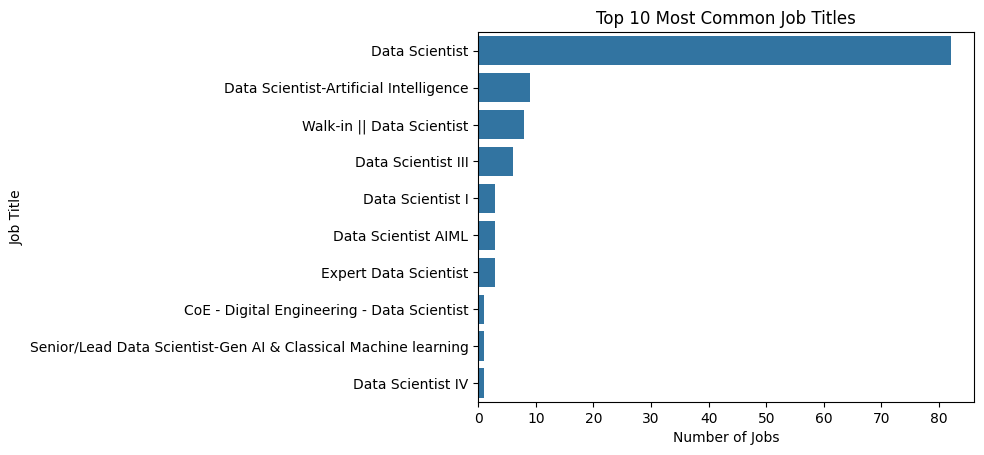

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
top_titles = df["title"].value_counts().head(10)

sns.barplot(
    x=top_titles.values,
    y=top_titles.index
)

plt.title("Top 10 Most Common Job Titles")
plt.xlabel("Number of Jobs")
plt.ylabel("Job Title")
plt.show()

In [9]:
len(df[df["title"] == "Data Scientist"]["company"].unique())

60

Why didn't we directly plot company vs title?

We have:

86 unique companies
46 unique job titles

If I put all of them into one graph, I'd get:

86 × 46 = 3,956 possible combinations.

Most of those combinations don't even exist.

So the graph would be a giant sea of zeros and become impossible to read.

Let's focus on the top 10 companies.

In [10]:
top_companies = df["company"].value_counts().head(10).index

In [11]:
company_title_data = df[df["company"].isin(top_companies)]

Think of crosstab as:

Count how often combinations of two categorical variables occur.

In [12]:
company_title = pd.crosstab(
    company_title_data["company"],
    company_title_data["title"]
)

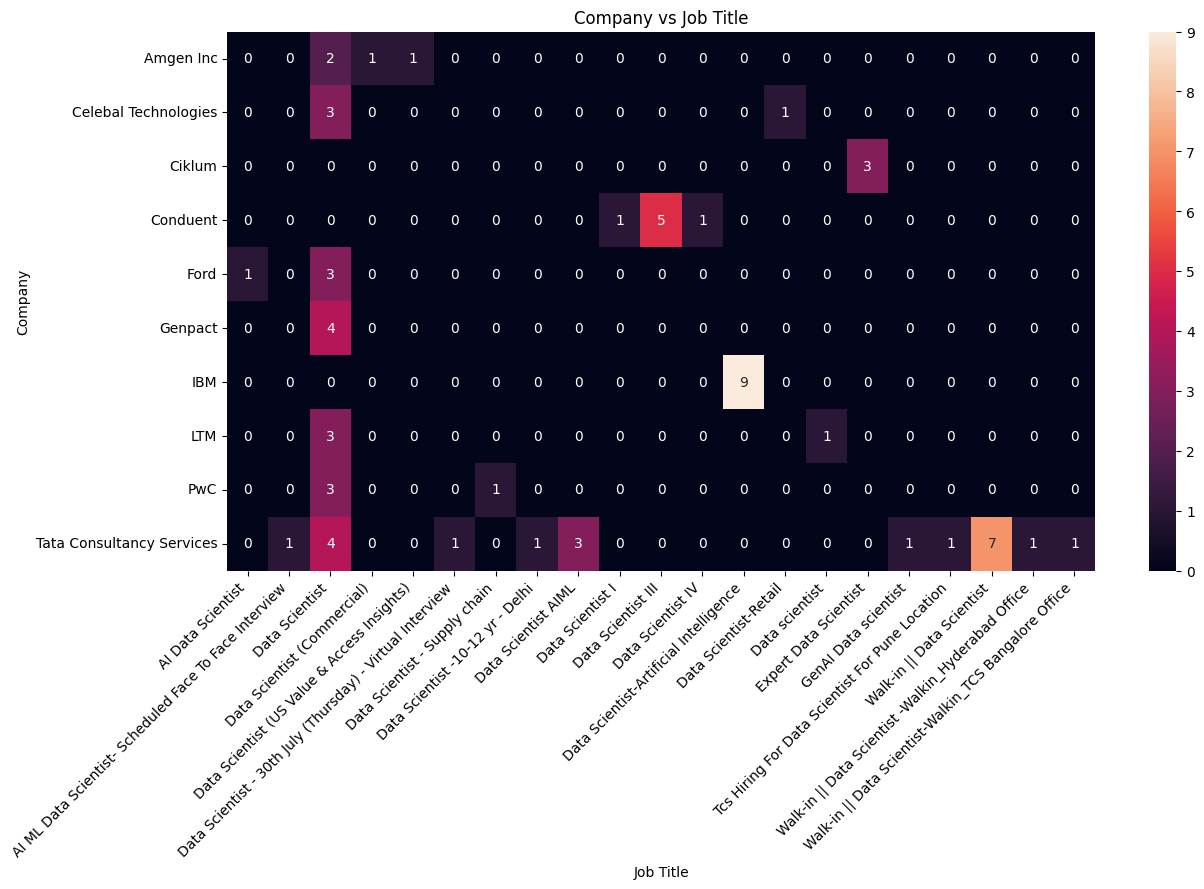

In [13]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    company_title,
    annot=True,
    fmt="d"
)

plt.title("Company vs Job Title")
plt.xlabel("Job Title")
plt.ylabel("Company")
plt.xticks(rotation=45, ha="right")
plt.show()

In [14]:
company_exp_data = df.dropna(subset=["experience_level"])

In [15]:
company_exp_data = company_exp_data[
    company_exp_data["company"].isin(top_companies)
]

In [16]:
company_exp = pd.crosstab(
    company_exp_data["company"],
    company_exp_data["experience_level"]
)

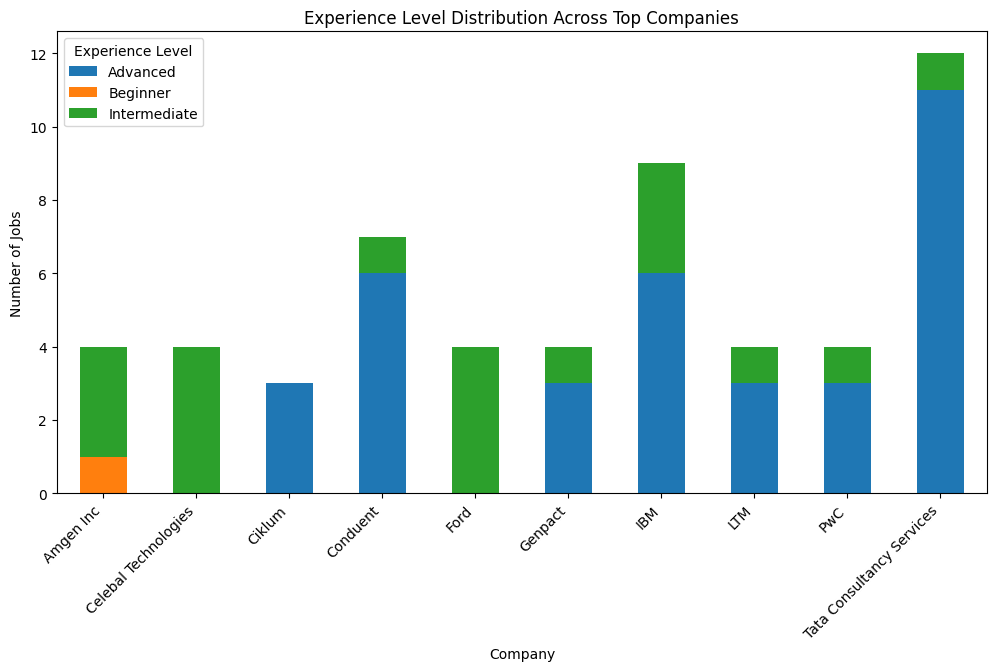

In [17]:
company_exp.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Experience Level Distribution Across Top Companies")
plt.xlabel("Company")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Experience Level")
plt.show()

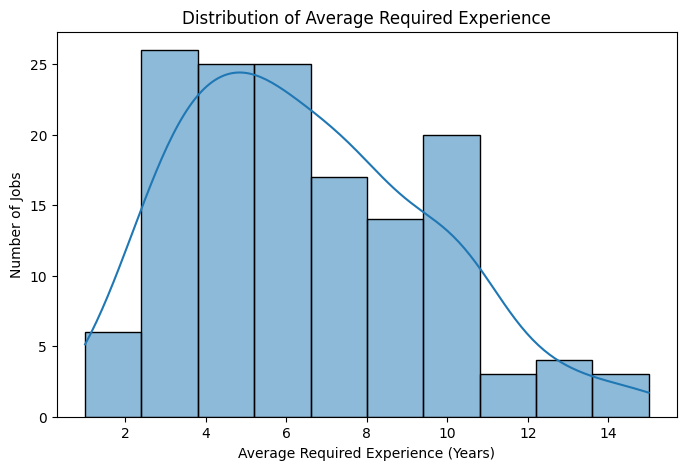

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="avg_experience",
    bins=10,
    kde=True
)

plt.title("Distribution of Average Required Experience")
plt.xlabel("Average Required Experience (Years)")
plt.ylabel("Number of Jobs")
plt.show()

In [19]:
##Location analysis
all_locations = []

for locations in df["location_list"]:
    all_locations.extend(locations)

In [20]:
location_counts = pd.Series(all_locations).value_counts()

In [21]:
location_counts.head(15)

'    398
a    212
u    197
e    165
[    153
]    153
n    139
r    137
     108
l     84
g     80
d     78
B     64
i     48
b     47
Name: count, dtype: int64

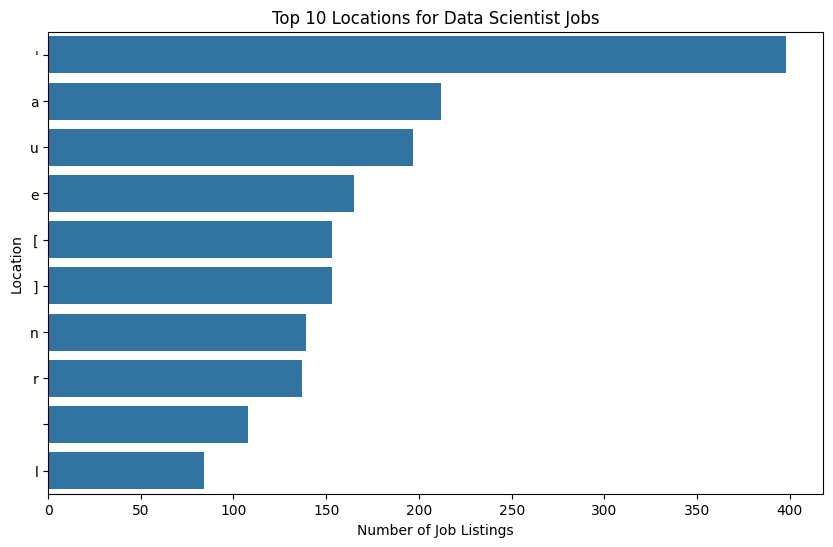

In [22]:
top_locations = location_counts.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 10 Locations for Data Scientist Jobs")
plt.xlabel("Number of Job Listings")
plt.ylabel("Location")
plt.show()

In [23]:
df['title'].value_counts()

title
Data Scientist                                                    82
Data Scientist-Artificial Intelligence                             9
Walk-in || Data Scientist                                          8
Data Scientist III                                                 6
Data Scientist I                                                   3
Data Scientist AIML                                                3
Expert Data Scientist                                              3
CoE - Digital Engineering - Data Scientist                         1
Senior/Lead Data Scientist-Gen AI & Classical Machine learning     1
Data Scientist IV                                                  1
Data Scientist - Supply chain                                      1
Data Scientist with R programming                                  1
Machine Learning Engineer / Data Scientist                         1
Sr. Data Scientist - Marketing & Customer Analytics                1
Tcs Hiring For Data Scientis

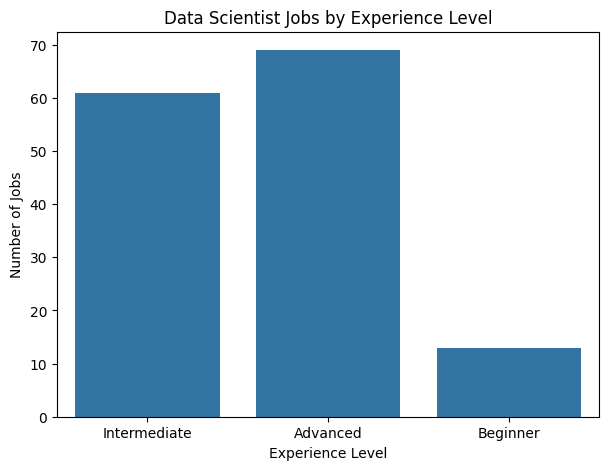

In [24]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="experience_level")

plt.title("Data Scientist Jobs by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Number of Jobs")
plt.show()

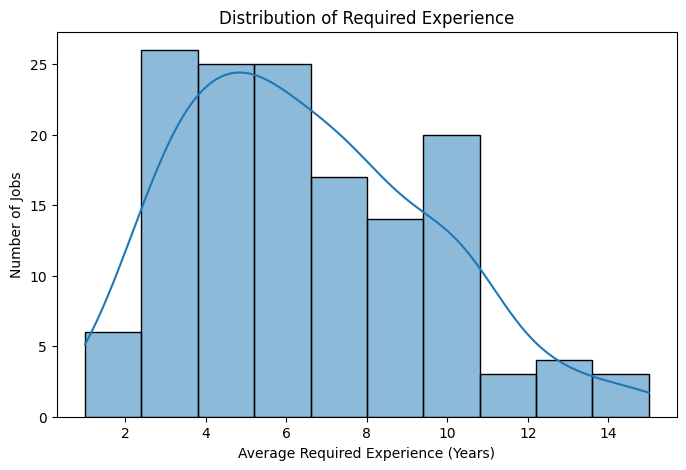

In [25]:
##REquired experience
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="avg_experience", bins=10, kde=True)

plt.title("Distribution of Required Experience")
plt.xlabel("Average Required Experience (Years)")
plt.ylabel("Number of Jobs")
plt.show()

In [26]:
location_exp_data = df[
    ["location_list", "experience_level"]
].dropna(subset=["experience_level"]).explode("location_list")

In [27]:
location_exp = pd.crosstab(
    location_exp_data["location_list"],
    location_exp_data["experience_level"]
)

In [28]:
location_exp_top = location_exp.loc[
    location_exp.index.intersection(top_locations.index)
]

In [29]:
import ast

df["skills"] = df["skills"].apply(ast.literal_eval)
df["skills"].apply(type).value_counts()

skills
<class 'list'>    153
Name: count, dtype: int64

In [30]:
all_skills = []

for skills in df["skills"]:
    all_skills.extend(skills)

skill_counts = pd.Series(all_skills).value_counts() #stored skill counts in descending order so top_skills head(20) 

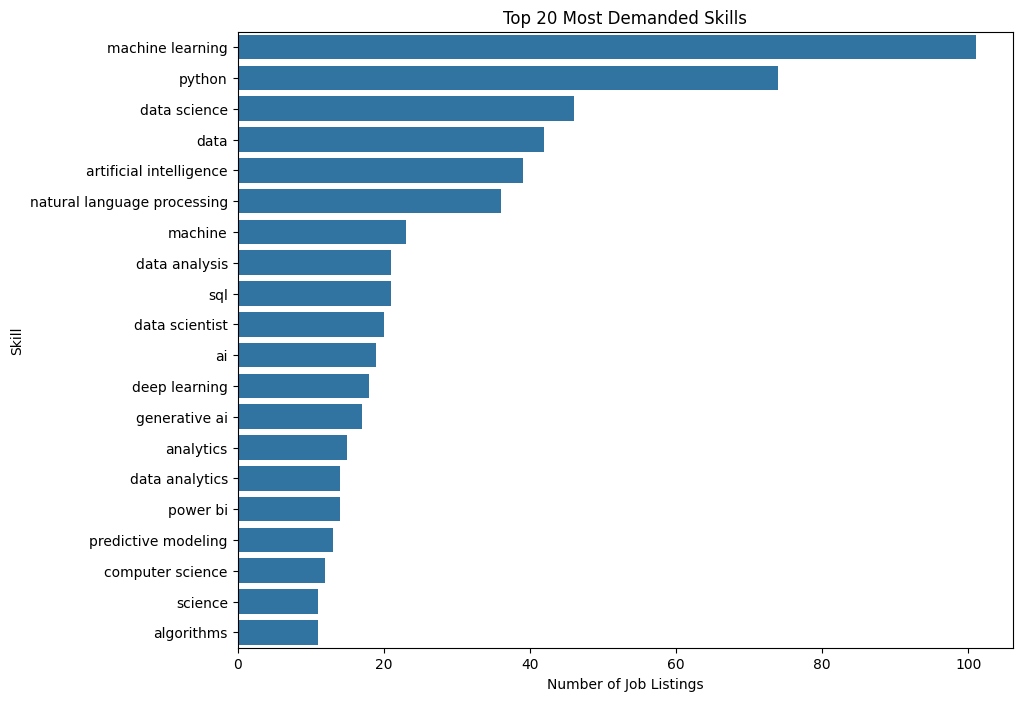

In [31]:
top_skills = skill_counts.head(20)

plt.figure(figsize=(10,8))
sns.barplot(
    x=top_skills.values,
    y=top_skills.index
)

plt.title("Top 20 Most Demanded Skills")
plt.xlabel("Number of Job Listings")
plt.ylabel("Skill")
plt.show()

In [32]:
skill_exp_data = df[
    ["skills", "experience_level"]
].dropna(subset=["experience_level"]).explode("skills")

In [33]:
skill_exp = pd.crosstab(
    skill_exp_data["skills"],
    skill_exp_data["experience_level"]
)

In [34]:
top_15_skills = skill_counts.head(15).index

skill_exp_top = skill_exp.loc[
    skill_exp.index.intersection(top_15_skills)
]

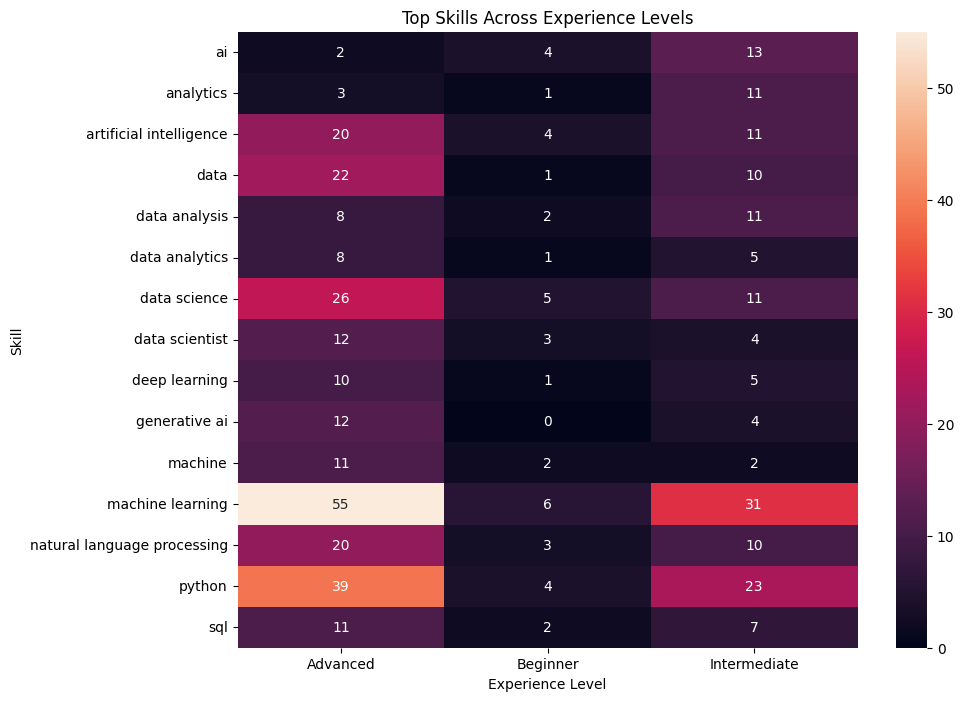

In [35]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    skill_exp_top,
    annot=True,
    fmt="d"
)

plt.title("Top Skills Across Experience Levels")
plt.xlabel("Experience Level")
plt.ylabel("Skill")
plt.show()

In [36]:
import ast

df["location_list"] = df["location_list"].apply(ast.literal_eval)
df["location_list"].apply(type).value_counts()

location_list
<class 'list'>    153
Name: count, dtype: int64

In [37]:
df["location_list"] = df["location_list"].apply(
    lambda locations: [location.strip() for location in locations]
)

In [38]:
all_locations = []

for locations in df["location_list"]:
    all_locations.extend(locations)

location_counts = pd.Series(all_locations).value_counts()

In [39]:
location_counts.head(15)

Bengaluru             61
Hyderabad             31
Pune                  30
Chennai               20
Gurugram              15
Mumbai                 8
Kolkata                5
Noida                  5
Bangalore Rural        3
Mumbai (All Areas)     3
India                  3
Delhi / Ncr            3
Ahmedabad              3
Remote                 2
Ahmedabad(Gota)        1
Name: count, dtype: int64

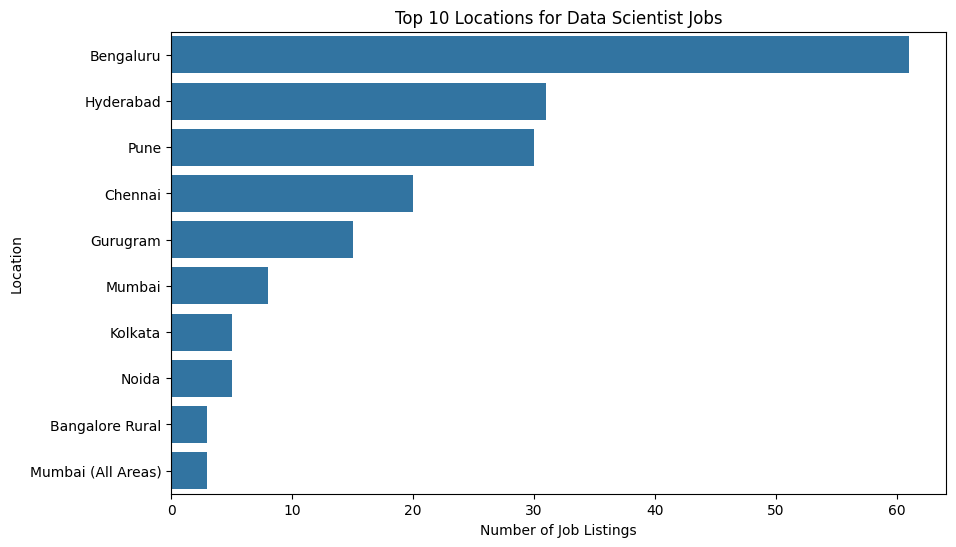

In [40]:
top_locations = location_counts.head(10)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 10 Locations for Data Scientist Jobs")
plt.xlabel("Number of Job Listings")
plt.ylabel("Location")
plt.show()

In [41]:
location_counts.index.tolist()

['Bengaluru',
 'Hyderabad',
 'Pune',
 'Chennai',
 'Gurugram',
 'Mumbai',
 'Kolkata',
 'Noida',
 'Bangalore Rural',
 'Mumbai (All Areas)',
 'India',
 'Delhi / Ncr',
 'Ahmedabad',
 'Remote',
 'Ahmedabad(Gota)',
 'Coimbatore',
 'Nagercoil',
 'Jaipur',
 'Chenani',
 'Delhi',
 'New Delhi']

In [42]:
location_exp_data = df[
    ["location_list", "experience_level"]
].dropna(subset=["experience_level"]).explode("location_list")

In [43]:
location_exp = pd.crosstab(
    location_exp_data["location_list"],
    location_exp_data["experience_level"]
)

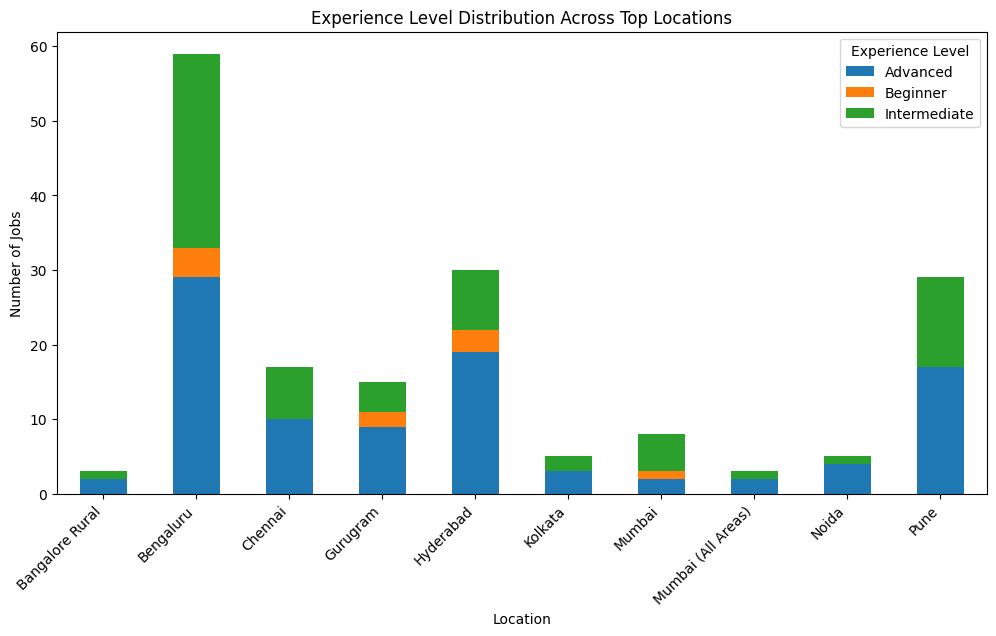

In [44]:
location_exp_top = location_exp.loc[
    location_exp.index.intersection(top_locations.index)
]
location_exp_top.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Experience Level Distribution Across Top Locations")
plt.xlabel("Location")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Experience Level")
plt.show()

In [45]:
company_location_data = df[
    ["company", "location_list"]
].explode("location_list")

In [46]:
company_location = pd.crosstab(
    company_location_data["company"],
    company_location_data["location_list"]
)

In [47]:
company_location_top = company_location.loc[
    company_location.index.intersection(top_companies),
    company_location.columns.intersection(top_locations.index)
]

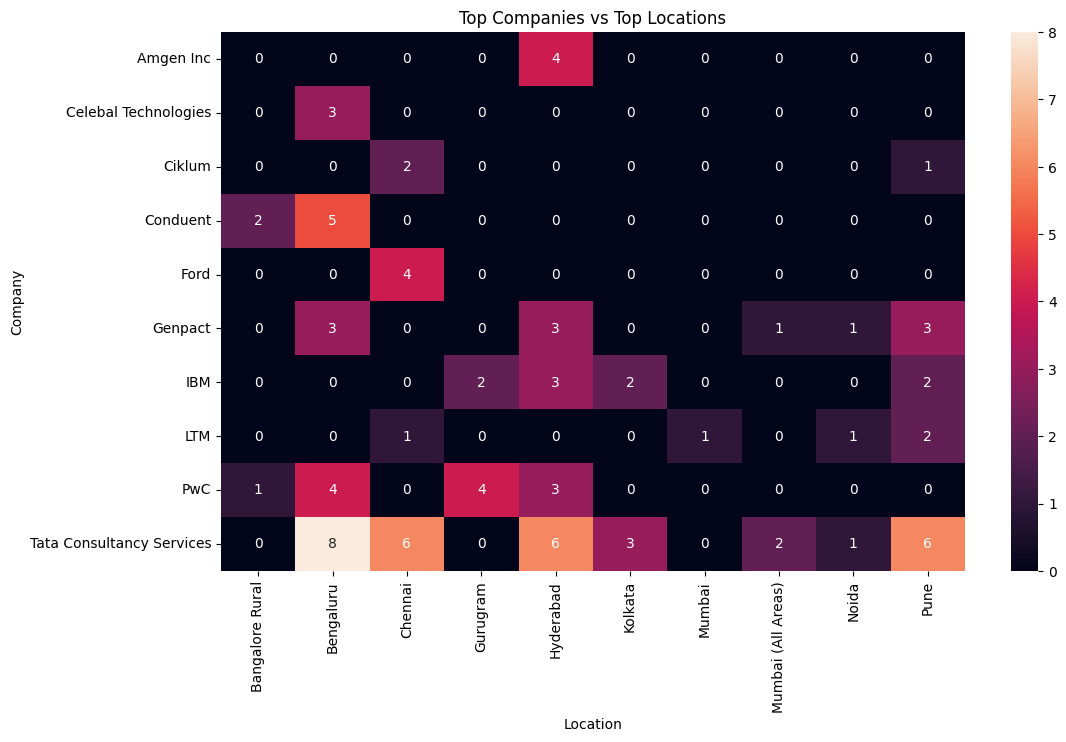

In [48]:
plt.figure(figsize=(12,7))

sns.heatmap(
    company_location_top,
    annot=True,
    fmt="d"
)

plt.title("Top Companies vs Top Locations")
plt.xlabel("Location")
plt.ylabel("Company")
plt.show()

In [49]:
company_skill_data = df[
    ["company", "skills"]
].explode("skills")

In [50]:
company_skill = pd.crosstab(
    company_skill_data["company"],
    company_skill_data["skills"]
)

In [51]:
company_skill_top=company_skill.head(15)

In [52]:
##description
df["description_length"] = df["description"].str.len()

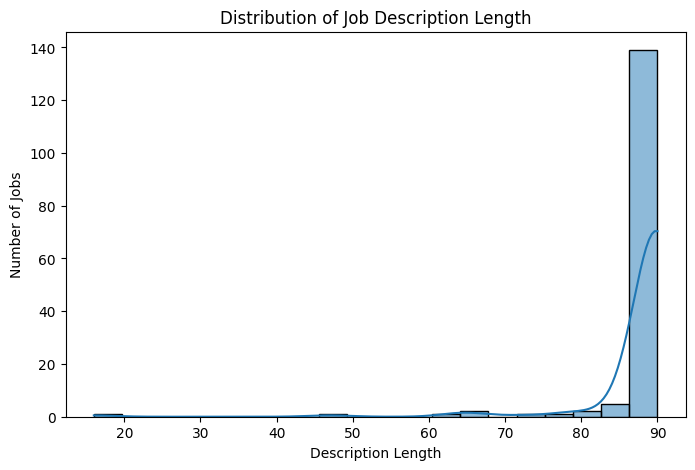

In [53]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="description_length",
    bins=20,
    kde=True
)

plt.title("Distribution of Job Description Length")
plt.xlabel("Description Length")
plt.ylabel("Number of Jobs")
plt.show()

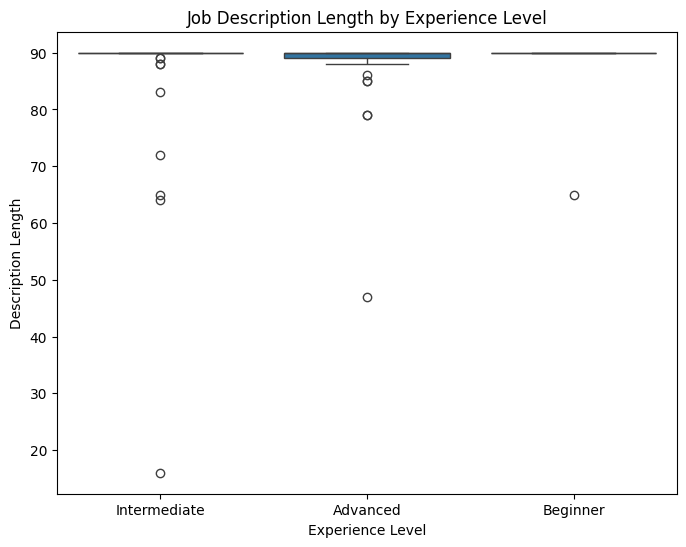

In [54]:
plt.figure(figsize=(8,6))

sns.boxplot(
    data=df,
    x="experience_level",
    y="description_length"
)

plt.title("Job Description Length by Experience Level")
plt.xlabel("Experience Level")
plt.ylabel("Description Length")
plt.show()

In [55]:
from itertools import combinations
from collections import Counter

skill_pairs = Counter()

for skills in df["skills"]:
    pairs = combinations(sorted(set(skills)), 2)
    skill_pairs.update(pairs)

In [56]:
skill_pairs.most_common(20)

[(('machine learning', 'python'), 62),
 (('data', 'machine learning'), 36),
 (('data science', 'machine learning'), 35),
 (('machine learning', 'natural language processing'), 34),
 (('artificial intelligence', 'machine learning'), 31),
 (('natural language processing', 'python'), 28),
 (('data', 'python'), 26),
 (('data science', 'python'), 23),
 (('machine', 'machine learning'), 23),
 (('data', 'machine'), 22),
 (('artificial intelligence', 'python'), 19),
 (('data analysis', 'machine learning'), 16),
 (('generative ai', 'machine learning'), 16),
 (('deep learning', 'machine learning'), 15),
 (('machine learning', 'sql'), 15),
 (('data', 'data science'), 15),
 (('machine', 'python'), 15),
 (('python', 'sql'), 14),
 (('artificial intelligence', 'data'), 14),
 (('artificial intelligence', 'natural language processing'), 14)]

In [57]:
df['rating'].describe()

count    153.000000
mean       3.533333
std        0.424264
min        2.000000
25%        3.300000
50%        3.500000
75%        3.900000
max        4.800000
Name: rating, dtype: float64

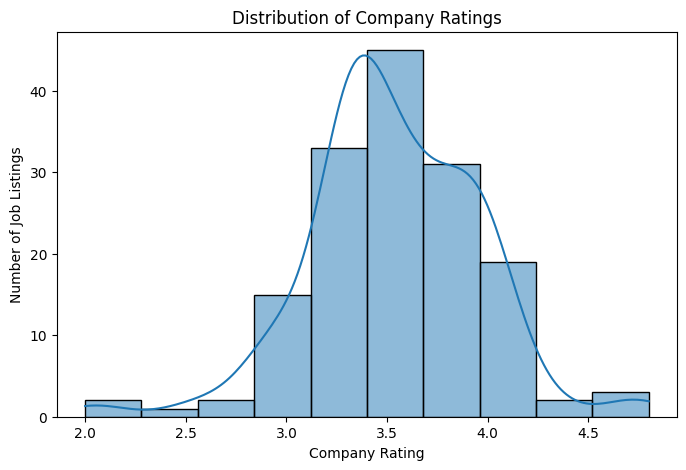

In [58]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="rating",
    bins=10,
    kde=True
)

plt.title("Distribution of Company Ratings")
plt.xlabel("Company Rating")
plt.ylabel("Number of Job Listings")

plt.show()

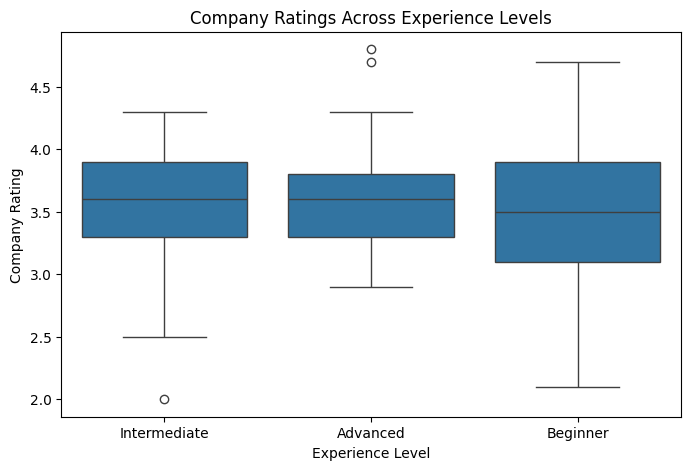

In [59]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="experience_level",
    y="rating"
)

plt.title("Company Ratings Across Experience Levels")
plt.xlabel("Experience Level")
plt.ylabel("Company Rating")

plt.show()

In [60]:
df.head(5)

,title,company,rating,experience,location,description,skills,min_experience,max_experience,avg_experience,experience_level,location_clean,location_list,description_length
0,Data Scientist,Kotak Mahindra Bank,3.6,3-7 Yrs,"Mumbai, Bengaluru",Skill requirements: . Masters or Bachelor s De...,"[sas, machine learning, analytics, python, sql...",3.0,7.0,5.0,Intermediate,"Mumbai, Bengaluru","[Mumbai, Bengaluru]",90
1,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Experience in developing and deploying AI / Ge...,"[data science, artificial intelligence, machin...",NaN,NaN,NaN,NaN,Chennai,[Chennai],78
2,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Roles and ResponsibilitiesDesign and develop d...,"[data science, artificial intelligence, machin...",NaN,NaN,NaN,NaN,Chennai,[Chennai],90
3,Data Scientist-Artificial Intelligence,IBM,3.9,3-5 Yrs,Kolkata,Your role and responsibilitiesAs a Data Scient...,"[data, security management, python, data analy...",3.0,5.0,4.0,Intermediate,Kolkata,[Kolkata],90
4,Walk-in || Data Scientist,Tata Consultancy Services,3.3,08 Aug,Chennai,Implementing MLOps practices for model deploym...,"[artificial intelligence, machine learning, py...",NaN,NaN,NaN,NaN,Chennai,[Chennai],90


In [61]:
df.to_csv('job.csv',index=False)

In [62]:
##for eda findings check the EDA_findings.docx file 